In [1]:
import torch
import torch.nn as nn

### Weight initialisation (Randomly)

In [2]:
model = nn.Sequential(
    nn.Linear(10, 32),
    nn.ReLU(),
    nn.Linear(32, 2),
)

In [3]:
model = nn.Linear(10, 2)
# The weights and biases are initialised using random procedures

### Data shuffling

In [4]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Creating a synthetic dataset
dataset = datasets.FakeData(
    size=100,
    image_size=(3, 32, 32),
    num_classes=10,
    transform=transforms.ToTensor()
)

In [5]:
# Create a Data Loader
loader = DataLoader(
    dataset=dataset,
    batch_size=32,
    shuffle=True
)

print(loader)

In [6]:
# Iterate through the dataset
for images, labels in loader:
    print(f"Images: {images.shape}")
    print(f"Labels: ", labels)

Images: torch.Size([32, 3, 32, 32])
Labels:  tensor([0, 2, 0, 1, 8, 1, 9, 1, 5, 9, 0, 4, 4, 3, 7, 1, 3, 6, 8, 6, 1, 0, 1, 3,
        0, 4, 3, 0, 6, 1, 8, 7])
Images: torch.Size([32, 3, 32, 32])
Labels:  tensor([1, 3, 9, 7, 1, 4, 3, 8, 6, 3, 9, 4, 9, 9, 1, 7, 3, 0, 1, 7, 4, 2, 9, 9,
        9, 4, 4, 2, 8, 7, 2, 1])
Images: torch.Size([32, 3, 32, 32])
Labels:  tensor([8, 7, 2, 5, 3, 3, 6, 7, 3, 6, 7, 1, 5, 1, 3, 5, 8, 6, 6, 3, 9, 4, 1, 5,
        0, 3, 7, 4, 6, 2, 5, 7])
Images: torch.Size([4, 3, 32, 32])
Labels:  tensor([6, 6, 0, 7])


In [7]:
# To understand randomness in the above, compare the order of samples across multiple iterations (epochs)

from torch.utils.data import TensorDataset

# Create 100 samples
features = torch.arange(100).unsqueeze(1)
labels = torch.arange(100)

print(features[:10])
print(labels[:10])

tensor([[0],
        [1],
        [2],
        [3],
        [4],
        [5],
        [6],
        [7],
        [8],
        [9]])
tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])


In [8]:
# Create a dataset instance
dataset = TensorDataset(features, labels)

# Create DataLoader
loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

# Test three epochs
for epoch in range(3):
    print(f"\nEpoch {epoch + 1}")

    for features, labels in loader:
        print(labels.tolist())


Epoch 1
[47, 35, 31, 34, 67, 83, 22, 77, 14, 69, 13, 80, 24, 41, 29, 56, 89, 5, 85, 30, 33, 2, 19, 99, 65, 25, 27, 32, 55, 86, 52, 0]
[93, 87, 45, 64, 1, 4, 98, 40, 11, 44, 90, 96, 9, 26, 23, 71, 79, 94, 37, 74, 12, 54, 36, 28, 51, 17, 58, 91, 15, 72, 92, 10]
[46, 8, 18, 95, 66, 81, 42, 88, 68, 48, 70, 62, 43, 21, 7, 16, 59, 53, 49, 75, 76, 84, 38, 3, 63, 57, 61, 73, 97, 50, 60, 20]
[39, 78, 6, 82]

Epoch 2
[21, 60, 35, 4, 72, 40, 29, 36, 99, 63, 73, 13, 2, 81, 53, 15, 30, 22, 46, 27, 44, 61, 45, 90, 10, 84, 43, 37, 92, 50, 98, 7]
[69, 57, 75, 58, 25, 47, 52, 31, 5, 34, 56, 14, 6, 74, 38, 68, 80, 97, 51, 71, 94, 86, 93, 96, 55, 82, 8, 12, 79, 42, 65, 54]
[41, 95, 67, 11, 1, 49, 23, 28, 9, 89, 70, 32, 16, 87, 0, 59, 24, 33, 64, 39, 3, 19, 91, 20, 85, 62, 83, 26, 77, 48, 78, 17]
[18, 88, 66, 76]

Epoch 3
[97, 23, 77, 87, 46, 43, 47, 18, 6, 90, 26, 60, 99, 53, 58, 3, 31, 80, 4, 55, 44, 27, 98, 32, 67, 19, 39, 95, 66, 24, 54, 68]
[59, 0, 64, 62, 8, 52, 96, 5, 36, 84, 73, 91, 70, 50, 57, 8

### Random Data Augmentation

In [9]:
from torchvision import transforms
import matplotlib.pyplot as plt

In [10]:
dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

0


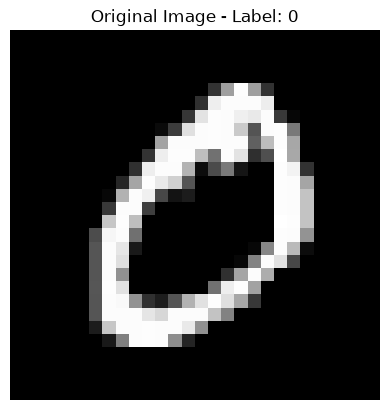

In [11]:
image, label = dataset[1]
print(label)

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Original Image - Label: {label}")
plt.axis("Off")
plt.show()

In [12]:
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15)
]
)


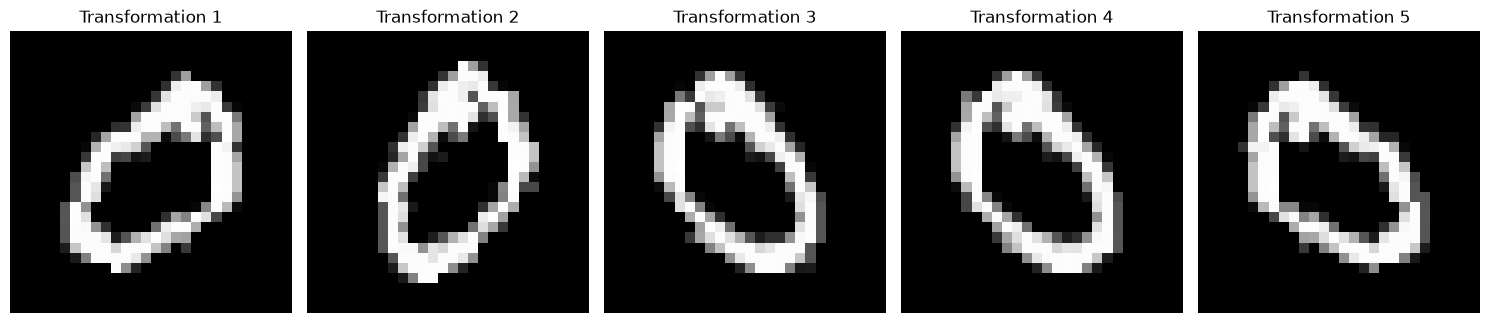

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i in range(5):

    transformed_image = transform(image)

    axes[i].imshow(transformed_image.squeeze(), cmap="gray")
    axes[i].set_title(f"Transformation {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()